# PS-49: Hand Gesture Recognition for Touchless Control

**Course:** Deep Learning — Challenge-Based Learning (CBL)  
**Register Number:** RA2311026050180  
**Problem Statement:** PS-49  
**Dataset:** LeapGestRecog — 20,000 near-infrared images from 10 subjects  
**Dataset source:** [Kaggle — Hand Gesture Recognition Database (LeapGestRecog)](https://www.kaggle.com/datasets/gti-upm/leapgestrecog)

## Experimental objective
Train CNN-based classifiers to recognise the ten prescribed hand gestures. The central experimental constraint is **subject-level generalisation**: no image from a test subject may occur in training or validation. Candidate models are selected using validation data only; the held-out test set is evaluated once after model selection.

## Required workflow
1. Load and inspect the images, class distribution, subject IDs, and sample images.
2. Create a reproducible subject-disjoint train/validation/test split.
3. Train a scratch CNN and an ImageNet-pretrained MobileNetV2 candidate.
4. Select one candidate using validation macro-F1 (validation accuracy as a tie-breaker).
5. Evaluate the selected model once on the untouched test subjects.
6. Save the per-class report, confusion matrix, learning curves, error examples, split manifest, and model.

> **Important:** Run every cell from top to bottom in Google Colab. Do not insert test images into training or use test performance to change hyperparameters. All reported performance values must come from the executed notebook; no result is pre-filled in this template.

**Runtime note:** This notebook automatically detects whether Colab has allocated a GPU. If only a CPU runtime is available, it uses 96 × 96 inputs, batch size 32, and shorter training limits (up to 8 epochs per candidate). The complete subject-disjoint dataset is retained; runtime-dependent settings are recorded in the results metadata.


## 1. Runtime and package setup

In [1]:
!pip -q install kagglehub seaborn scikit-learn

In [2]:
import os
import json
import random
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
GPU_AVAILABLE = bool(tf.config.list_physical_devices('GPU'))

# Automatically choose a practical configuration for the available Colab runtime.
# CPU settings reduce compute cost while retaining the full subject-disjoint dataset.
if GPU_AVAILABLE:
    RUNTIME_PROFILE = 'GPU'
    IMAGE_SIZE = 128
    BATCH_SIZE = 64
    BASELINE_EPOCHS = 20
    TRANSFER_EPOCHS = 18
else:
    RUNTIME_PROFILE = 'CPU'
    IMAGE_SIZE = 96
    BATCH_SIZE = 32
    BASELINE_EPOCHS = 8
    TRANSFER_EPOCHS = 8

AUTOTUNE = tf.data.AUTOTUNE
OUTPUT_DIR = Path('/content/ps49_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print('Python:', platform.python_version())
print('TensorFlow:', tf.__version__)
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Runtime profile:', RUNTIME_PROFILE)
print('GPU devices:', tf.config.list_physical_devices('GPU'))
print('Image size:', IMAGE_SIZE)
print('Batch size:', BATCH_SIZE)
print('Baseline maximum epochs:', BASELINE_EPOCHS)
print('MobileNetV2 maximum epochs:', TRANSFER_EPOCHS)
print('Random seed:', SEED)
print('Output directory:', OUTPUT_DIR)


Python: 3.13.18
TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 2.2.3
Runtime profile: CPU
GPU devices: []
Image size: 96
Batch size: 32
Baseline maximum epochs: 8
MobileNetV2 maximum epochs: 8
Random seed: 42
Output directory: /content/ps49_outputs


## 2. Download and locate the dataset

In [3]:
import kagglehub

DATASET_PATH = Path(kagglehub.dataset_download('gti-upm/leapgestrecog'))
print('KaggleHub dataset path:', DATASET_PATH)

# KaggleHub may return a parent directory containing an additional
# leapGestRecog folder. Select the directory whose immediate children
# are the numbered subject folders (00–09 or 0–9).
candidates = [DATASET_PATH]
candidates.extend(
    p for p in DATASET_PATH.rglob('*')
    if p.is_dir() and p.name.lower() == 'leapgestrecog'
)

DATA_ROOT = None
for candidate in candidates:
    if not candidate.exists() or not candidate.is_dir():
        continue
    subject_dirs = [p for p in candidate.iterdir() if p.is_dir() and p.name.isdigit()]
    if len(subject_dirs) >= 10:
        DATA_ROOT = candidate
        break

if DATA_ROOT is None:
    raise FileNotFoundError(
        'Could not locate the ten numbered subject folders. Inspect DATASET_PATH and update DATA_ROOT.'
    )

print('Resolved image root:', DATA_ROOT)
print('Top-level subject folders:', sorted(p.name for p in DATA_ROOT.iterdir() if p.is_dir()))

Using Colab cache for faster access to the 'leapgestrecog' dataset.
KaggleHub dataset path: /kaggle/input/leapgestrecog
Resolved image root: /kaggle/input/leapgestrecog/leapGestRecog
Top-level subject folders: ['00', '01', '02', '03', '04', '05', '06', '07', '08', '09']


## 3. Build the image index and verify the ten classes

In [4]:
GESTURE_MAP = {
    '01_palm': 'Palm',
    '02_l': 'L',
    '03_fist': 'Fist',
    '04_fist_moved': 'Fist moved',
    '05_thumb': 'Thumb',
    '06_index': 'Index',
    '07_ok': 'OK',
    '08_palm_moved': 'Palm moved',
    '09_c': 'C',
    '10_down': 'Down',
}
CLASS_NAMES = list(GESTURE_MAP.values())
CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}

records = []
for image_path in sorted(DATA_ROOT.rglob('*.png')):
    gesture_folder = image_path.parent.name
    subject_id = image_path.parent.parent.name
    if gesture_folder not in GESTURE_MAP:
        continue
    records.append({
        'path': str(image_path),
        'subject_id': subject_id,
        'gesture_folder': gesture_folder,
        'label': GESTURE_MAP[gesture_folder],
        'label_id': CLASS_TO_ID[GESTURE_MAP[gesture_folder]],
    })

df = pd.DataFrame(records)
if df.empty:
    raise RuntimeError('No PNG images were indexed. Check the resolved dataset directory.')

subjects = sorted(df['subject_id'].unique().tolist())
print('Total images:', len(df))
print('Number of subjects:', len(subjects))
print('Subjects:', subjects)
print('Classes:', CLASS_NAMES)

class_counts = (
    df.groupby('label')['path'].count()
      .reindex(CLASS_NAMES)
      .rename('image_count')
      .reset_index()
)
display(class_counts)

subject_class_counts = pd.crosstab(df['subject_id'], df['label']).reindex(columns=CLASS_NAMES)
display(subject_class_counts)

assert len(CLASS_NAMES) == 10, 'The PS-49 task requires ten gesture classes.'
assert len(subjects) >= 3, 'At least three distinct subjects are required for grouped train/validation/test splits.'
assert set(df['label'].unique()) == set(CLASS_NAMES), 'One or more expected gesture classes are missing.'

Total images: 20000
Number of subjects: 10
Subjects: ['00', '01', '02', '03', '04', '05', '06', '07', '08', '09']
Classes: ['Palm', 'L', 'Fist', 'Fist moved', 'Thumb', 'Index', 'OK', 'Palm moved', 'C', 'Down']


,label,image_count
0,Palm,2000
1,L,2000
2,Fist,2000
3,Fist moved,2000
4,Thumb,2000
5,Index,2000
6,OK,2000
7,Palm moved,2000
8,C,2000
9,Down,2000


label,Palm,L,Fist,Fist moved,Thumb,Index,OK,Palm moved,C,Down
subject_id,,,,,,,,,,
00,200,200,200,200,200,200,200,200,200,200
01,200,200,200,200,200,200,200,200,200,200
02,200,200,200,200,200,200,200,200,200,200
03,200,200,200,200,200,200,200,200,200,200
04,200,200,200,200,200,200,200,200,200,200
05,200,200,200,200,200,200,200,200,200,200
06,200,200,200,200,200,200,200,200,200,200
07,200,200,200,200,200,200,200,200,200,200
08,200,200,200,200,200,200,200,200,200,200


## 4. Explore representative images and class balance

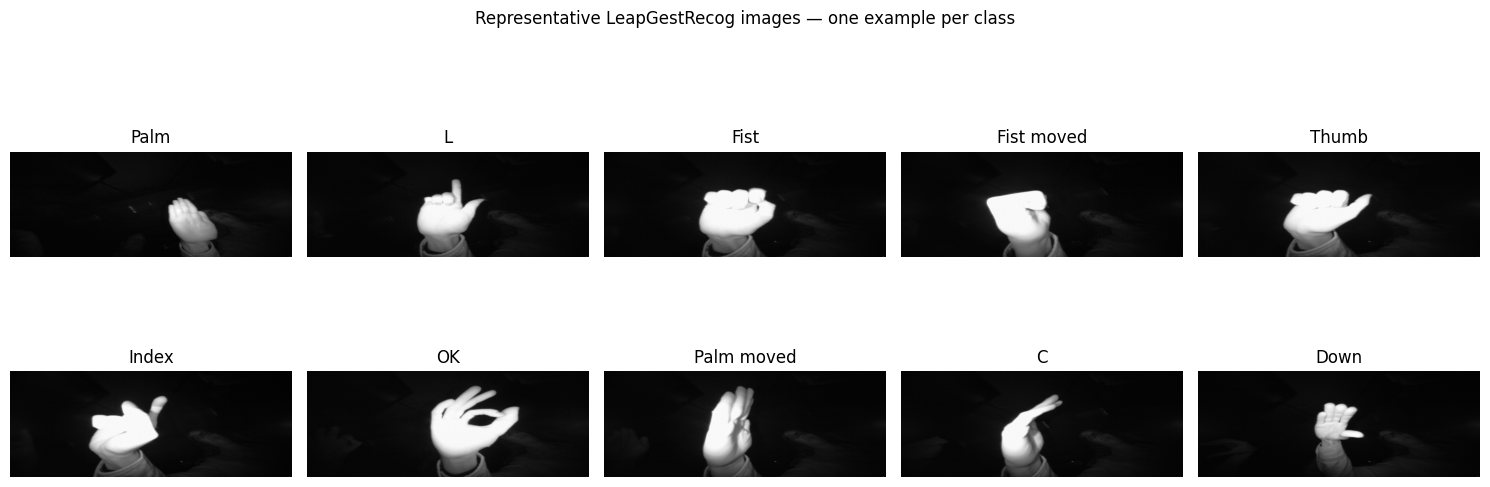

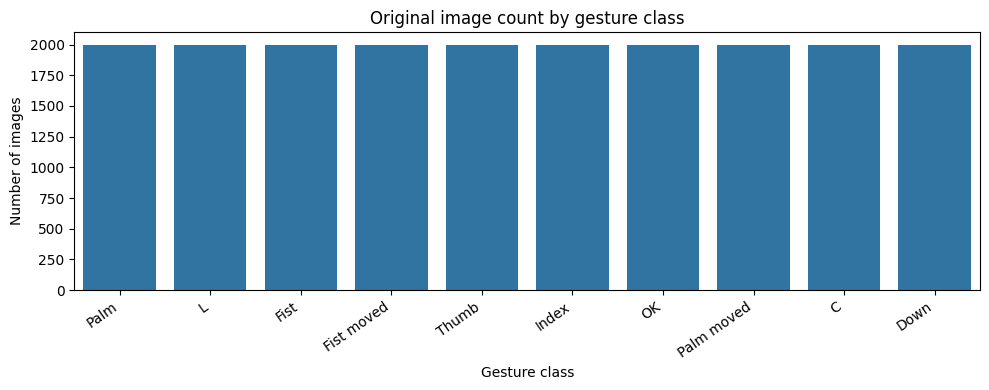

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, label in zip(axes.flat, CLASS_NAMES):
    sample_path = df.loc[df['label'] == label, 'path'].iloc[0]
    image = tf.io.decode_png(tf.io.read_file(sample_path), channels=1).numpy().squeeze()
    ax.imshow(image, cmap='gray')
    ax.set_title(label)
    ax.axis('off')
plt.suptitle('Representative LeapGestRecog images — one example per class')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'sample_images.png', dpi=220, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 4))
sns.barplot(data=class_counts, x='label', y='image_count')
plt.title('Original image count by gesture class')
plt.xlabel('Gesture class')
plt.ylabel('Number of images')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=220, bbox_inches='tight')
plt.show()

## 5. Subject-disjoint data split (PS-49 critical requirement)

The images are grouped by the subject directory. A deterministic shuffle of the **subject IDs** assigns 60% of subjects to training, 20% to validation, and 20% to testing. This keeps all images belonging to a person in exactly one split. The test subjects therefore remain unseen during training and model selection.

The split proportions refer to the number of subjects, not necessarily the exact number of images. The actual image counts are printed and saved below. If the faculty has provided a fixed subject split or balanced subset, use that allocation instead and document it.

In [6]:
if len(subjects) != 10:
    raise ValueError(
        f'Expected 10 subject folders for the published PS-49 dataset; found {len(subjects)}: {subjects}. '
        'Inspect the dataset version and revise the split transparently if needed.'
    )

rng = np.random.default_rng(SEED)
shuffled_subjects = rng.permutation(subjects).tolist()

n_train = 6
n_val = 2
train_subjects = shuffled_subjects[:n_train]
val_subjects = shuffled_subjects[n_train:n_train + n_val]
test_subjects = shuffled_subjects[n_train + n_val:]

train_df = df[df['subject_id'].isin(train_subjects)].copy().reset_index(drop=True)
val_df = df[df['subject_id'].isin(val_subjects)].copy().reset_index(drop=True)
test_df = df[df['subject_id'].isin(test_subjects)].copy().reset_index(drop=True)

# Explicit leakage checks: no subject may cross split boundaries.
assert set(train_subjects).isdisjoint(val_subjects)
assert set(train_subjects).isdisjoint(test_subjects)
assert set(val_subjects).isdisjoint(test_subjects)
assert set(train_df['subject_id']).isdisjoint(val_df['subject_id'])
assert set(train_df['subject_id']).isdisjoint(test_df['subject_id'])
assert set(val_df['subject_id']).isdisjoint(test_df['subject_id'])

split_summary = pd.DataFrame([
    {'split': 'Train', 'subjects': ', '.join(train_subjects), 'images': len(train_df)},
    {'split': 'Validation', 'subjects': ', '.join(val_subjects), 'images': len(val_df)},
    {'split': 'Test (unseen subjects)', 'subjects': ', '.join(test_subjects), 'images': len(test_df)},
])
display(split_summary)

split_manifest = pd.concat([
    train_df.assign(split='train'),
    val_df.assign(split='validation'),
    test_df.assign(split='test'),
], ignore_index=True)
split_manifest.to_csv(OUTPUT_DIR / 'split_manifest.csv', index=False)

split_class_counts = pd.crosstab(split_manifest['split'], split_manifest['label']).reindex(
    index=['train', 'validation', 'test'], columns=CLASS_NAMES, fill_value=0
)
display(split_class_counts)

for split_name, split_frame in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    missing = set(CLASS_NAMES) - set(split_frame['label'])
    if missing:
        raise ValueError(f'{split_name} split is missing classes: {sorted(missing)}')

print('Leakage check passed: train, validation, and test contain different subjects.')

,split,subjects,images
0,Train,"05, 06, 00, 07, 03, 02",12000
1,Validation,"04, 09",4000
2,Test (unseen subjects),"01, 08",4000


label,Palm,L,Fist,Fist moved,Thumb,Index,OK,Palm moved,C,Down
split,,,,,,,,,,
train,1200,1200,1200,1200,1200,1200,1200,1200,1200,1200
validation,400,400,400,400,400,400,400,400,400,400
test,400,400,400,400,400,400,400,400,400,400


Leakage check passed: train, validation, and test contain different subjects.


## 6. TensorFlow input pipeline and preprocessing

In [7]:
def load_and_preprocess(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_png(image_bytes, channels=1)
    image = tf.image.resize(image, [IMAGE_SIZE, IMAGE_SIZE], antialias=True)
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.int32)


def make_dataset(frame, training=False):
    paths = frame['path'].to_numpy()
    labels = frame['label_id'].to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(
            buffer_size=min(len(frame), 10000),
            seed=SEED,
            reshuffle_each_iteration=True,
        )
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# Class weights are derived only from training labels.
class_weight_values = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(len(CLASS_NAMES)),
    y=train_df['label_id'].to_numpy(),
)
class_weights = {int(i): float(w) for i, w in enumerate(class_weight_values)}
print('Training class weights:', class_weights)
print('Input tensor shape:', (IMAGE_SIZE, IMAGE_SIZE, 1))

Training class weights: {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0, 6: 1.0, 7: 1.0, 8: 1.0, 9: 1.0}
Input tensor shape: (96, 96, 1)


## 7. Candidate A — CNN trained from scratch

In [8]:
def make_augmentation(name='augmentation'):
    # No horizontal/vertical flips are used because mirroring may alter
    # gesture orientation and could change the semantic appearance of a class.
    return tf.keras.Sequential([
        tf.keras.layers.RandomRotation(0.04),
        tf.keras.layers.RandomZoom(0.08),
        tf.keras.layers.RandomTranslation(0.04, 0.04),
        tf.keras.layers.RandomContrast(0.10),
    ], name=name)


def build_baseline_cnn():
    inputs = tf.keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 1))
    x = make_augmentation('cnn_augmentation')(inputs)

    for filters, dropout_rate in [(32, 0.10), (64, 0.15), (128, 0.20), (256, 0.25)]:
        x = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation('relu')(x)
        x = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation('relu')(x)
        x = tf.keras.layers.MaxPooling2D()(x)
        x = tf.keras.layers.Dropout(dropout_rate)(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.35)(x)
    outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation='softmax')(x)
    model = tf.keras.Model(inputs, outputs, name='PS49_Baseline_CNN')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

baseline_model = build_baseline_cnn()
baseline_model.summary()

Model: "PS49_Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_augmentation (Sequential)   │ (None, 96, 96, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,208,746 (4.61 MB)

 Trainable params: 1,206,826 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 8. Train Candidate A

In [9]:
def train_candidate(model, train_data, validation_data, model_name, epochs):
    checkpoint_path = OUTPUT_DIR / f'{model_name}_best.keras'
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor='val_loss',
            save_best_only=True,
            verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=4,
            restore_best_weights=True,
            verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.3,
            patience=2,
            min_lr=1e-6,
            verbose=1,
        ),
        tf.keras.callbacks.TerminateOnNaN(),
    ]
    start = time.perf_counter()
    history = model.fit(
        train_data,
        validation_data=validation_data,
        epochs=epochs,
        class_weight=class_weights,
        callbacks=callbacks,
        verbose=1,
    )
    elapsed = time.perf_counter() - start
    best_model = tf.keras.models.load_model(checkpoint_path)
    print(f'{model_name} training time: {elapsed / 60:.2f} minutes')
    print(f'{model_name} best validation loss: {min(history.history["val_loss"]):.4f}')
    return best_model, history, elapsed

baseline_model, baseline_history, baseline_seconds = train_candidate(
    baseline_model, train_ds, val_ds, 'baseline_cnn', epochs=BASELINE_EPOCHS
)

Epoch 1/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6683 - loss: 1.0019
Epoch 1: val_loss improved from None to 7.41568, saving model to /content/ps49_outputs/baseline_cnn_best.keras

Epoch 1: finished saving model to /content/ps49_outputs/baseline_cnn_best.keras
375/375 ━━━━━━━━━━━━━━━━━━━━ 1319s 3s/step - accuracy: 0.8638 - loss: 0.4375 - val_accuracy: 0.1000 - val_loss: 7.4157 - learning_rate: 0.0010
Epoch 2/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9837 - loss: 0.0621
Epoch 2: val_loss improved from 7.41568 to 1.10465, saving model to /content/ps49_outputs/baseline_cnn_best.keras

Epoch 2: finished saving model to /content/ps49_outputs/baseline_cnn_best.keras
375/375 ━━━━━━━━━━━━━━━━━━━━ 1364s 4s/step - accuracy: 0.9843 - loss: 0.0583 - val_accuracy: 0.7398 - val_loss: 1.1046 - learning_rate: 0.0010
Epoch 3/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9885 - loss: 0.0398
Epoch 3: val_loss improved from 1.10465 to 0.14083, saving model to /conten

## 9. Candidate B — MobileNetV2 transfer learning

In [10]:
def build_mobilenetv2():
    inputs = tf.keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 1))
    x = make_augmentation('mobilenet_augmentation')(inputs)

    # MobileNetV2 expects three channels and input values in [-1, 1].
    # Replicate the near-infrared channel to RGB and apply the expected scaling.
    x = tf.keras.layers.Concatenate()([x, x, x])
    x = tf.keras.layers.Rescaling(scale=2.0, offset=-1.0)(x)

    backbone = tf.keras.applications.MobileNetV2(
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        include_top=False,
        weights='imagenet',
    )
    backbone.trainable = False
    x = backbone(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.40)(x)
    outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs, name='PS49_MobileNetV2')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

transfer_model = build_mobilenetv2()
transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "PS49_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 96, 96, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenet_augmenta… │ (None, 96, 96, 1) │          0 │ input_layer_2[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 96, 96, 3) │          0 │ mobilenet_augmen… │
│ (Concatenate)       │                   │            │ mobilenet_augmen… │
│                     │                   │            │ mobilenet_augmen… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 96, 96, 3) │          0 │ concatenate[0][0] │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_96 │ (None, 3, 3,      │  2,257,984 │ rescaling[0][0]   │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1280)      │      5,120 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │    163,968 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 128)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 10)        │      1,290 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,428,362 (9.26 MB)

 Trainable params: 167,818 (655.54 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

## 10. Train Candidate B

In [11]:
transfer_model, transfer_history, transfer_seconds = train_candidate(
    transfer_model, train_ds, val_ds, 'mobilenetv2', epochs=TRANSFER_EPOCHS
)

Epoch 1/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - accuracy: 0.8315 - loss: 0.5602
Epoch 1: val_loss improved from None to 0.19977, saving model to /content/ps49_outputs/mobilenetv2_best.keras

Epoch 1: finished saving model to /content/ps49_outputs/mobilenetv2_best.keras
375/375 ━━━━━━━━━━━━━━━━━━━━ 177s 453ms/step - accuracy: 0.9404 - loss: 0.2057 - val_accuracy: 0.9160 - val_loss: 0.1998 - learning_rate: 5.0000e-04
Epoch 2/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - accuracy: 0.9927 - loss: 0.0304
Epoch 2: val_loss did not improve from 0.19977
375/375 ━━━━━━━━━━━━━━━━━━━━ 168s 447ms/step - accuracy: 0.9937 - loss: 0.0262 - val_accuracy: 0.9193 - val_loss: 0.2195 - learning_rate: 5.0000e-04
Epoch 3/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 338ms/step - accuracy: 0.9961 - loss: 0.0173
Epoch 3: val_loss did not improve from 0.19977

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
375/375 ━━━━━━━━━━━━━━━━━━━━ 197s 434ms/step - accuracy: 0.9962 - loss: 0.0166 -

## 11. Compare candidates using validation data only

In [ ]:
def predict_labels(model, dataset):
    probabilities = model.predict(dataset, verbose=0)
    return probabilities.argmax(axis=1), probabilities

val_true = val_df['label_id'].to_numpy()
baseline_val_pred, baseline_val_prob = predict_labels(baseline_model, val_ds)
transfer_val_pred, transfer_val_prob = predict_labels(transfer_model, val_ds)

validation_comparison = pd.DataFrame([
    {
        'model': 'Baseline CNN',
        'validation_accuracy': accuracy_score(val_true, baseline_val_pred),
        'validation_macro_f1': f1_score(val_true, baseline_val_pred, average='macro'),
        'training_minutes': baseline_seconds / 60,
        'parameters': baseline_model.count_params(),
    },
    {
        'model': 'MobileNetV2',
        'validation_accuracy': accuracy_score(val_true, transfer_val_pred),
        'validation_macro_f1': f1_score(val_true, transfer_val_pred, average='macro'),
        'training_minutes': transfer_seconds / 60,
        'parameters': transfer_model.count_params(),
    },
]).sort_values(['validation_macro_f1', 'validation_accuracy'], ascending=False)

display(validation_comparison.style.format({
    'validation_accuracy': '{:.4f}',
    'validation_macro_f1': '{:.4f}',
    'training_minutes': '{:.2f}',
    'parameters': '{:,}',
}))
validation_comparison.to_csv(OUTPUT_DIR / 'validation_model_comparison.csv', index=False)

selected_name = validation_comparison.iloc[0]['model']
if selected_name == 'Baseline CNN':
    selected_model = baseline_model
    selected_history = baseline_history
    selected_training_seconds = baseline_seconds
    selected_checkpoint = OUTPUT_DIR / 'baseline_cnn_best.keras'
else:
    selected_model = transfer_model
    selected_history = transfer_history
    selected_training_seconds = transfer_seconds
    selected_checkpoint = OUTPUT_DIR / 'mobilenetv2_best.keras'

print('Selected using validation macro-F1:', selected_name)
print('The test set has not been evaluated yet.')

## 12. Learning curves

In [ ]:
def plot_history(history, title, file_name):
    h = history.history
    epochs = range(1, len(h['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, h['accuracy'], label='Training accuracy')
    axes[0].plot(epochs, h['val_accuracy'], label='Validation accuracy')
    axes[0].set_title('Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(epochs, h['loss'], label='Training loss')
    axes[1].plot(epochs, h['val_loss'], label='Validation loss')
    axes[1].set_title('Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / file_name, dpi=220, bbox_inches='tight')
    plt.show()

plot_history(baseline_history, 'Baseline CNN — training and validation', 'baseline_learning_curves.png')
plot_history(transfer_history, 'MobileNetV2 — training and validation', 'mobilenetv2_learning_curves.png')
plot_history(selected_history, f'Selected model: {selected_name}', 'selected_learning_curves.png')

## 13. Final evaluation on the untouched test subjects

This is the only section that evaluates the final selected model on the test split. Do not use these results to revise the architecture or hyperparameters. The test subjects were excluded from training and validation by construction.

In [14]:
# Final held-out test evaluation — run once after model selection.
test_true = test_df['label_id'].to_numpy()
test_probabilities = selected_model.predict(test_ds, verbose=1)
test_pred = test_probabilities.argmax(axis=1)

TEST_ACCURACY = float(accuracy_score(test_true, test_pred))
TEST_MACRO_F1 = float(f1_score(test_true, test_pred, average='macro'))

print(f'Selected model: {selected_name}')
print(f'Test subjects: {test_subjects}')
print(f'Test images: {len(test_df)}')
print(f'Test accuracy: {TEST_ACCURACY * 100:.2f}%')
print(f'Test macro-F1: {TEST_MACRO_F1:.4f}')

report_dict = classification_report(
    test_true,
    test_pred,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
report_table = pd.DataFrame(report_dict).T
print('\nPer-class test performance:')
display(report_table.loc[CLASS_NAMES, ['precision', 'recall', 'f1-score', 'support']].style.format({
    'precision': '{:.4f}', 'recall': '{:.4f}', 'f1-score': '{:.4f}', 'support': '{:.0f}'
}))

report_table.to_csv(OUTPUT_DIR / 'test_classification_report.csv')

125/125 ━━━━━━━━━━━━━━━━━━━━ 100s 801ms/step
Selected model: Baseline CNN
Test subjects: ['01', '08']
Test images: 4000
Test accuracy: 90.30%
Test macro-F1: 0.9034

Per-class test performance:


,precision,recall,f1-score,support
Palm,0.6496,0.8250,0.7269,400
L,1.0000,0.9350,0.9664,400
Fist,1.0000,0.7600,0.8636,400
Fist moved,0.9662,1.0000,0.9828,400
Thumb,0.9598,0.8350,0.8930,400
Index,1.0000,1.0000,1.0000,400
OK,0.9122,0.6750,0.7759,400
Palm moved,0.9070,1.0000,0.9512,400
C,1.0000,1.0000,1.0000,400
Down,0.7767,1.0000,0.8743,400


## 14. Confusion matrix

In [ ]:
cm = confusion_matrix(test_true, test_pred, labels=np.arange(len(CLASS_NAMES)))
cm_df = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)
cm_df.to_csv(OUTPUT_DIR / 'test_confusion_matrix.csv')

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_df, annot=True, fmt='d', cmap='Blues',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    cbar=True,
)
plt.title(f'Test confusion matrix — {selected_name}')
plt.xlabel('Predicted gesture')
plt.ylabel('Actual gesture')
plt.xticks(rotation=40, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'test_confusion_matrix.png', dpi=240, bbox_inches='tight')
plt.show()

## 15. Inspect at least four misclassified test images

In [ ]:
error_positions = np.flatnonzero(test_pred != test_true)
print('Misclassified test images:', len(error_positions), 'out of', len(test_df))

if len(error_positions) == 0:
    print('No test errors were observed. In this case, show the highest-confidence correct examples and state that no misclassified examples were available.')
else:
    n_show = min(8, len(error_positions))
    chosen_positions = error_positions[:n_show]
    ncols = 4
    nrows = int(np.ceil(n_show / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    error_records = []
    for ax, pos in zip(axes, chosen_positions):
        row = test_df.iloc[int(pos)]
        image = tf.io.decode_png(tf.io.read_file(row['path']), channels=1).numpy().squeeze()
        predicted_id = int(test_pred[pos])
        confidence = float(test_probabilities[pos, predicted_id])
        actual_label = CLASS_NAMES[int(test_true[pos])]
        predicted_label = CLASS_NAMES[predicted_id]

        ax.imshow(image, cmap='gray')
        ax.set_title(f'Actual: {actual_label}\nPredicted: {predicted_label}\nConfidence: {confidence:.1%}')
        ax.axis('off')
        error_records.append({
            'path': row['path'],
            'subject_id': row['subject_id'],
            'actual': actual_label,
            'predicted': predicted_label,
            'confidence': confidence,
        })

    for ax in axes[n_show:]:
        ax.axis('off')
    plt.suptitle('Misclassified examples from unseen test subjects')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'misclassified_test_examples.png', dpi=220, bbox_inches='tight')
    plt.show()
    display(pd.DataFrame(error_records))
    pd.DataFrame(error_records).to_csv(OUTPUT_DIR / 'misclassified_examples.csv', index=False)

### Manual interpretation of misclassified examples

Inspect each displayed error at full size and record a visual explanation only when supported by the image. Possible factors to investigate include similar hand silhouettes, overlapping finger contours, orientation, motion-related blur, partial hand visibility, or low contrast. These are prompts for inspection, not assumed causes. Complete the `likely_visual_reason` column before using the error analysis in the report.


In [ ]:
if len(error_positions) > 0:
    error_review = pd.DataFrame(error_records)
else:
    error_review = pd.DataFrame(columns=['path', 'subject_id', 'actual', 'predicted', 'confidence'])

error_review['likely_visual_reason'] = ''  # Complete this after inspecting the displayed examples.
display(error_review)
error_review.to_csv(OUTPUT_DIR / 'misclassified_examples_for_review.csv', index=False)


## 16. Result summary, model saving, and reproducibility artifacts

Use the printed test metrics and saved plots when drafting the report. Record the actual split subject IDs, versions, selected model, training duration, and class-wise metrics. Do not report validation scores as test scores.

In [18]:
selected_model.save(OUTPUT_DIR / 'selected_ps49_model.keras')

per_class_results = {}
for label in CLASS_NAMES:
    per_class_results[label] = {
        'precision': float(report_dict[label]['precision']),
        'recall': float(report_dict[label]['recall']),
        'f1_score': float(report_dict[label]['f1-score']),
        'support': int(report_dict[label]['support']),
    }

results = {
    'problem_statement': 'PS-49 Hand Gesture Recognition for Touchless Control',
    'dataset': 'LeapGestRecog',
    'total_indexed_images': int(len(df)),
    'classes': CLASS_NAMES,
    'seed': SEED,
    'runtime_profile': RUNTIME_PROFILE,
    'image_size': [IMAGE_SIZE, IMAGE_SIZE],
    'batch_size': BATCH_SIZE,
    'training_configuration': {
        'baseline_cnn': {'optimizer': 'Adam', 'learning_rate': 0.001, 'max_epochs': BASELINE_EPOCHS, 'early_stopping_patience': 4},
        'mobilenetv2': {'optimizer': 'Adam', 'learning_rate': 0.0005, 'max_epochs': TRANSFER_EPOCHS, 'backbone': 'ImageNet-pretrained MobileNetV2 (frozen)'},
        'augmentation': 'random rotation, zoom, translation, and contrast; no flips',
        'loss': 'sparse categorical cross-entropy',
    },
    'train_subjects': train_subjects,
    'validation_subjects': val_subjects,
    'test_subjects_unseen': test_subjects,
    'train_images': int(len(train_df)),
    'validation_images': int(len(val_df)),
    'test_images': int(len(test_df)),
    'selected_model_by_validation_macro_f1': selected_name,
    'test_accuracy': TEST_ACCURACY,
    'test_macro_f1': TEST_MACRO_F1,
    'selected_model_training_minutes': float(selected_training_seconds / 60),
    'selected_model_parameters': int(selected_model.count_params()),
    'tensorflow_version': tf.__version__,
    'python_version': platform.python_version(),
    'per_class_test_metrics': per_class_results,
}

with open(OUTPUT_DIR / 'results_summary.json', 'w') as f:
    json.dump(results, f, indent=2)

print(json.dumps(results, indent=2))

{
  "problem_statement": "PS-49 Hand Gesture Recognition for Touchless Control",
  "dataset": "LeapGestRecog",
  "total_indexed_images": 20000,
  "classes": [
    "Palm",
    "L",
    "Fist",
    "Fist moved",
    "Thumb",
    "Index",
    "OK",
    "Palm moved",
    "C",
    "Down"
  ],
  "seed": 42,
  "runtime_profile": "CPU",
  "image_size": [
    96,
    96
  ],
  "batch_size": 32,
  "training_configuration": {
    "baseline_cnn": {
      "optimizer": "Adam",
      "learning_rate": 0.001,
      "max_epochs": 8,
      "early_stopping_patience": 4
    },
    "mobilenetv2": {
      "optimizer": "Adam",
      "learning_rate": 0.0005,
      "max_epochs": 8,
      "backbone": "ImageNet-pretrained MobileNetV2 (frozen)"
    },
    "augmentation": "random rotation, zoom, translation, and contrast; no flips",
    "loss": "sparse categorical cross-entropy"
  },
  "train_subjects": [
    "05",
    "06",
    "00",
    "07",
    "03",
    "02"
  ],
  "validation_subjects": [
    "04",
    "09"
 

## 17. Download the evidence package

The ZIP contains the trained model, subject split manifest, metrics, confusion matrix, training plots, and error examples. The executed notebook itself should also be saved with outputs and pushed to GitHub.

In [19]:
import shutil
from google.colab import files

zip_path = shutil.make_archive('/content/PS49_results', 'zip', OUTPUT_DIR)
print('Created:', zip_path)
files.download(zip_path)

Created: /content/PS49_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 18. Submission checklist and academic integrity

- [ ] All notebook cells execute successfully from top to bottom.
- [ ] The class counts and sample images are shown.
- [ ] The fixed subject-wise split is printed and saved; no subject crosses splits.
- [ ] The two candidates are compared using validation data only.
- [ ] The selected model is evaluated once on the held-out test subjects.
- [ ] Test accuracy, per-class precision/recall/F1, macro-F1, and confusion matrix are included.
- [ ] At least four misclassified test images are shown and interpreted (or explain why none exist).
- [ ] Training and validation accuracy/loss curves are retained.
- [ ] Python/TensorFlow versions, random seed, split manifest, and training configuration are saved.
- [ ] The executed notebook is saved as `RA2311026050180_PS49.ipynb` and pushed to GitHub.
- [ ] The report is named `RA2311026050180_PS49_Report.pdf` and is no longer than two pages.
- [ ] Dataset and any adapted external code/tutorials are cited.
- [ ] AI assistance is declared accurately; the student can explain every notebook cell during the viva.

**AI-assistance disclosure (edit to reflect actual use):** “An AI assistant was used for guidance in structuring and reviewing parts of the workflow. The student executed the notebook, verified the experimental outputs, and reviewed the interpretation of results.”

**Dataset reference:** GTI-UPM, *Hand Gesture Recognition Database (LeapGestRecog)*, Kaggle. https://www.kaggle.com/datasets/gti-upm/leapgestrecog